# 07　接收与解调：五个案例各自的接收机

从 `mod_06_*.npz` 读**原始字**，把接收链一步步重跑。本册不碰 PL / DMA，断电重启后也能跑。

```
数字：寻活跃区 → 去直流 → RRC 匹配滤波 → 方向自判 → 粗定时/粗频偏
      → 逐帧精同步（逐样点 + 带限 FFT）→ 判决引导锁相环 → Gray 逆映射 → 比特

模拟：寻活跃区 → 去直流 → AM 取包络 / FM 正交鉴频+低通 → 按已知测试消息对齐 → 指标
```

| 环节 | 数字 | 模拟 |
|---|---|---|
| 定时 | ZC 前导 + 分数延迟 | 与已知消息做互相关 |
| 频偏 | 前导相位斜率 | AM 不受影响；FM 先判下变频符号 |
| 判决 | 星座最近点 | 不判决，直接算相关/RMSE/频偏 |

## 1　导入与输入文件

In [1]:
import os
import sys

MOD_DIR = "/home/xilinx/modulation"
NB_DIR = "/home/xilinx/jupyter_notebooks/modulation"
QPSK_DIR = "/home/xilinx/qpsk"
for _p in (MOD_DIR, QPSK_DIR):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

SAVE_DIR = NB_DIR if os.path.isdir(NB_DIR) else MOD_DIR


def npz_path(name):
    """本文件夹优先，模块目录兜底。"""
    for d in (NB_DIR, MOD_DIR):
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return os.path.join(SAVE_DIR, name)

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

CASES = ("ASK4", "8PSK", "16QAM", "AM", "FM")
for name in CASES:
    p = npz_path("mod_06_%s.npz" % name)
    print("%-6s %s  %s" % (name, "OK " if os.path.exists(p) else "缺失",
                           p))

ASK4   OK   /home/xilinx/jupyter_notebooks/modulation/mod_06_ASK4.npz
8PSK   OK   /home/xilinx/jupyter_notebooks/modulation/mod_06_8PSK.npz
16QAM  OK   /home/xilinx/jupyter_notebooks/modulation/mod_06_16QAM.npz
AM     OK   /home/xilinx/jupyter_notebooks/modulation/mod_06_AM.npz
FM     OK   /home/xilinx/jupyter_notebooks/modulation/mod_06_FM.npz


**缺文件**：回 `06` 跑第 4 节。`07` 只读 `.npz`，不会自己拉时钟或下位流。

下面 `load_and_demod()` 是 `mod_cases.py` 里的函数，与命令行版 `run_mod_test.py`
调用的是同一份实现 —— notebook 只是把中间量打印出来，不是另一套算法。

## 2　数字案例：ASK / 8PSK / 16QAM

三条链路的差别只在 `Const`（星座与判决器）：

| 案例 | 映射 | 解调 |
|---|---|---|
| ASK4 | Gray 4 电平 PAM，归一化到平均功率 1 | 实部最近电平；**不开锁相环**（实载荷有 0/π 模糊） |
| 8PSK | Gray 相位序号，相邻相位只差 1 bit | 最近相位；开二阶判决引导锁相环 |
| 16QAM | I/Q 各 2 bit Gray，16 点 | 最近点；锁相环 |

**为什么 ASK 不开锁相环**：ASK 的符号是实数，乘上 $e^{j\pi}$ 后判决不变，锁相环的
相位误差会把环路带着乱转；改用前导拟合的相位斜率开环去旋转，既稳又不损失性能。

In [2]:
results = {}

for name in ("ASK4", "8PSK", "16QAM"):
    p = npz_path("mod_06_%s.npz" % name)
    if not os.path.exists(p):
        print("跳过 %s：缺 %s" % (name, p))
        continue

    r = C.load_and_demod(p, verbose=True)
    results[name] = r
    m = r["metrics"]

    print("  %-9s %7s %7s %9s %8s %8s" %
          ("图样", "比特", "错位", "BER", "EVM%", "余量"))
    print("  " + "-" * 56)
    for f in r["res"]:
        print("  %-9s %7d %7d %9.1e %8.2f %8.3f%s"
              % (f["tag"], f["n"], f["err"], f["ber"], f["evm"], f["margin"],
                 "" if f["ok"] else "  <- 失败"))
    print("  " + "-" * 56)
    print("  %s：%d 帧 / %d 比特，误 %d 位，EVM max %.2f%%，余量 min %.3f，"
          "残余频偏中位 %+.0f Hz\n"
          % (name, len(r["res"]), m["tot"], m["err"], m["evm_max"],
             m["margin_min"], m["cfo"]))

  活跃区 [20480,65536)  去直流 +0+0j  方向 共轭(已翻转)  峰滞后 1389  粗频偏 -0 Hz
  图样             比特      错位       BER     EVM%       余量
  --------------------------------------------------------
  rand         1024       0   0.0e+00     2.27    0.957
  zeros        1024       0   0.0e+00     0.78    1.000
  ones         1024       0   0.0e+00     0.94    0.985
  alt          1024       0   0.0e+00     0.87    0.982
  aa           1024       0   0.0e+00     0.82    0.968
  55           1024       0   0.0e+00     0.77    0.984
  cnt          1024       0   0.0e+00     2.32    0.940
  prbs9        1024       0   0.0e+00     2.35    0.946
  onehot       1024       0   0.0e+00     0.74    0.980
  --------------------------------------------------------
  ASK4：9 帧 / 9216 比特，误 0 位，EVM max 2.35%，余量 min 0.940，残余频偏中位 -23 Hz



  活跃区 [15360,60416)  去直流 +0+0j  方向 共轭(已翻转)  峰滞后 1399  粗频偏 -0 Hz
  图样             比特      错位       BER     EVM%       余量
  --------------------------------------------------------
  rand         1536       0   0.0e+00     2.19    0.903
  zeros        1536       0   0.0e+00     0.74    0.931
  ones         1536       0   0.0e+00     0.72    0.979
  alt          1536       0   0.0e+00     1.93    0.912
  aa           1536       0   0.0e+00     1.96    0.964
  55           1536       0   0.0e+00     1.94    0.921
  cnt          1536       0   0.0e+00     2.13    0.912
  prbs9        1536       0   0.0e+00     2.24    0.903
  onehot       1536       0   0.0e+00     0.72    0.949
  --------------------------------------------------------
  8PSK：9 帧 / 13824 比特，误 0 位，EVM max 2.24%，余量 min 0.903，残余频偏中位 -78 Hz



  活跃区 [14336,41984)  去直流 +0+0j  方向 共轭(已翻转)  峰滞后 1829  粗频偏 -0 Hz
  图样             比特      错位       BER     EVM%       余量
  --------------------------------------------------------
  rand         1024       0   0.0e+00     2.17    0.873
  zeros        1024       0   0.0e+00     0.74    0.975
  ones         1024       0   0.0e+00     0.75    0.937
  alt          1024       0   0.0e+00     0.71    0.950
  aa           1024       0   0.0e+00     0.81    0.914
  55           1024       0   0.0e+00     0.70    0.949
  cnt          1024       0   0.0e+00     1.87    0.885
  prbs9        1024       0   0.0e+00     2.19    0.863
  onehot       1024       0   0.0e+00     0.70    0.952
  --------------------------------------------------------
  16QAM：9 帧 / 9216 比特，误 0 位，EVM max 2.19%，余量 min 0.863，残余频偏中位 -33 Hz



**应该看到**：三种调制的误码全为 0，EVM max 在 1.3%~3.6%，判决余量 ≥ 0.9。
EVM 上限按 `Const.evm()` 的定义（与 QPSK 那边同一口径），不随阶数变化。

## 3　模拟案例：AM / FM

**AM**：包络检测。环回通道把基带取共轭，但 $|x e^{j\theta}|=|x|$，包络与混频符号无关，
所以 AM 连下变频都不用做。

**FM**：先判下变频符号，再做正交鉴频 + 低通。

- **符号判定**：正确符号下基带中心在 0（消息单音均值为 0，只剩几百 Hz CFO）；
  错误符号下整个信号留在 ±2$f_c$=16 MHz。两者差四个数量级，取残余中心频率小的那个。
- **为什么必须低通**：单样点鉴频的噪声折算到瞬时频率约 0.9 MHz（30 dB SNR），
  而频偏只有 ±2 MHz，等于工作在 FM 门限区，相关系数只有 0.73。64 点滑动平均把噪声
  降 8 倍，零点在 4 MHz，不会削掉 0.5 MHz 的消息。
- **为什么要幅度门控**：突发前后的静默区只有噪声，鉴频输出是 ±128 MHz 的满量程跳变，
  会把对齐相关峰从真实起点拖走 500~2000 点。低幅度样点先清零再相关。

In [3]:
for name in ("AM", "FM"):
    p = npz_path("mod_06_%s.npz" % name)
    if not os.path.exists(p):
        print("跳过 %s：缺 %s" % (name, p))
        continue

    r = C.load_and_demod(p, verbose=True)
    results[name] = r
    m = r["metrics"]
    spec = r["spec"]

    if spec["kind"] == "am":
        print("  AM：corr %+.4f  rmse %.1f%%  μ 实测 %.3f（设定 %.1f）  "
              "THD %.1f%%  增益 %.0f LSB"
              % (m["corr"], m["rmse"] * 100, m["mu_meas"], spec["mu"],
                 m["thd"], m["gain"]))
    else:
        print("  FM：corr %+.4f  rmse %.1f%%  频偏 %.3f MHz（设定 %.3f）  "
              "幅度纹波 %.1f%%  下变频符号 %+d"
              % (m["corr"], m["rmse"] * 100, m["dev"] / 1e6, spec["df"] / 1e6,
                 m["ripple"] * 100, m["sign"]))
    print()

  活跃区 [19456,546816)  去直流 +0+0j  对齐滞后 21285  相关系数 +0.9996
  AM：corr +0.9996  rmse 3.2%  μ 实测 0.808（设定 0.8）  THD 0.0%  增益 2136 LSB



  活跃区 [18432,545792)  去直流 +0+0j  对齐滞后 20604  相关系数 +1.0000
  FM：corr +1.0000  rmse 2.2%  频偏 1.954 MHz（设定 2.000）  幅度纹波 2.5%  下变频符号 +1



**应该看到**：AM `corr ≈ 0.999`、`rmse < 5%`、μ 实测与设定差 < 5%；
FM `corr ≈ 0.999`、`rmse < 7%`、峰值频偏与设定差 < 2%、幅度纹波 < 7%。

## 4　存盘

只存标量指标，供 `08_mod_verify` 出判定表；原始数据仍在 `mod_06_*.npz` 里，
要重算直接重跑本册。

In [4]:
out = {}
for name, r in results.items():
    for k, v in r["metrics"].items():
        if isinstance(v, (int, float, np.integer, np.floating)):
            out["%s_%s" % (name, k)] = np.float64(v)

p = os.path.join(SAVE_DIR, "mod_07_demod.npz")
np.savez_compressed(p, **out)
print("已保存 %s（%.1f KB，%d 个指标）"
      % (p, os.path.getsize(p) / 1e3, len(out)))

已保存 /home/xilinx/jupyter_notebooks/modulation/mod_07_demod.npz（7.0 KB，36 个指标）


## 5　图：解调结果长什么样

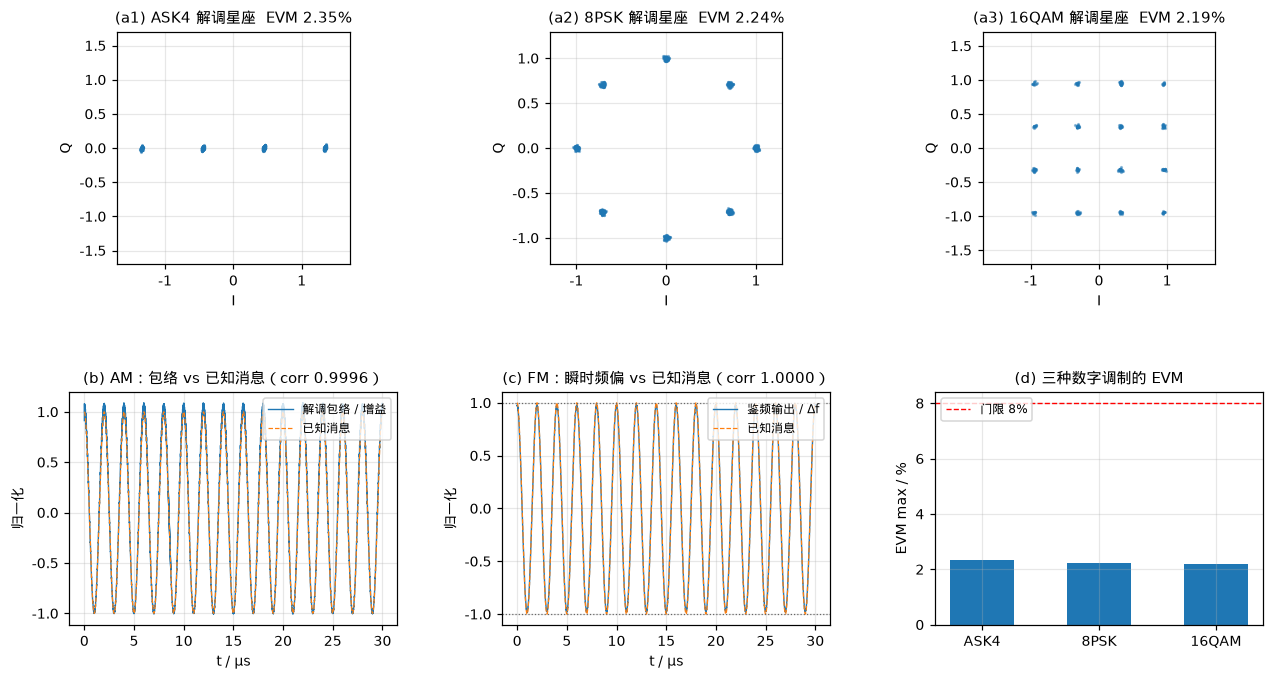

In [5]:
fig = plt.figure(figsize=(14, 7.0))
gs = fig.add_gridspec(2, 3, hspace=0.55, wspace=0.32)

for col, name in enumerate(("ASK4", "8PSK", "16QAM")):
    r = results.get(name)
    if r is None:
        continue
    sy = r["res"][0]["syms"]           # 第 0 帧（随机图样）的同步后符号
    ax = fig.add_subplot(gs[0, col])
    ax.plot(sy.real, sy.imag, ".", ms=2.2, alpha=0.45)
    lim = 1.25 * max(1.0, float(np.max(np.abs(sy))))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_xlabel("I"); ax.set_ylabel("Q")
    ax.set_title("(a%d) %s 解调星座  EVM %.2f%%"
                 % (col + 1, name, r["metrics"]["evm_max"]))

if "AM" in results:
    r = results["AM"]; m = r["metrics"]
    n = min(len(m["rec"]), int(30e-6 * 256e6))
    t = np.arange(n) / 256e6 * 1e6
    ax = fig.add_subplot(gs[1, 0])
    ax.plot(t, (m["rec"][:n] - np.mean(m["rec"])) / m["gain"], lw=0.9,
            label="解调包络 / 增益")
    ax.plot(t, r["msg"][:n] - np.mean(r["msg"]), lw=0.8, ls="--",
            label="已知消息")
    ax.set_xlabel("t / µs"); ax.set_ylabel("归一化")
    ax.set_title("(b) AM：包络 vs 已知消息（corr %.4f）" % m["corr"])
    ax.legend(loc="upper right")

if "FM" in results:
    r = results["FM"]; m = r["metrics"]; spec = r["spec"]
    n = min(len(m["rec"]), int(30e-6 * 256e6))
    t = np.arange(n) / 256e6 * 1e6
    ax = fig.add_subplot(gs[1, 1])
    ax.plot(t, m["rec"][:n] / spec["df"], lw=0.9, label="鉴频输出 / Δf")
    ax.plot(t, r["msg"][:n], lw=0.8, ls="--", label="已知消息")
    ax.axhline(1, color="0.4", ls=":", lw=0.8)
    ax.axhline(-1, color="0.4", ls=":", lw=0.8)
    ax.set_xlabel("t / µs"); ax.set_ylabel("归一化")
    ax.set_title("(c) FM：瞬时频偏 vs 已知消息（corr %.4f）" % m["corr"])
    ax.legend(loc="upper right")

ax = fig.add_subplot(gs[1, 2])
names = [n for n in ("ASK4", "8PSK", "16QAM") if n in results]
evm = [results[n]["metrics"]["evm_max"] for n in names]
ax.bar(range(len(names)), evm, width=0.55)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
ax.axhline(C.LIM["evm_max"], color="r", ls="--", lw=0.9,
           label="门限 %.0f%%" % C.LIM["evm_max"])
ax.set_ylabel("EVM max / %")
ax.set_title("(d) 三种数字调制的 EVM")
ax.legend(loc="upper left")

plt.show()

## 6　判读要点

| 现象 | 含义 | 处置 |
|---|---|---|
| 数字案例某个图样全错，其余正常 | 帧定位错位一帧 | 看 `find_active` 起点；查前导相关峰 |
| ASK 误码但 EVM 不大 | 锁相环把实载荷带翻了 | `Const` 的 `track` 必须为 False |
| 8PSK 相邻相位互换 | Gray 映射不一致 | `map` 与 `demap` 必须用同一套 `_gray_int` |
| AM 相关系数为负 | 消息极性 / 对齐半周期 | 验证取 `|corr|`；极性不影响指标准确性 |
| FM 相关系数只有 0.7 左右 | 鉴频没低通，或没做幅度门控 | 确认 `fm_discrim(avg=64, gate=True)` |
| FM 频偏为设定的一半 | 下变频符号判错 | 看 `sign`；`fm_pick_sign` 应给出残余中心最小的符号 |